In [1]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

print("Random seed:", SEED)

TensorFlow version: 2.17.0
Random seed: 42


In [2]:
# Research review: Despite the crude filename, this cell selects nifty50_2007_to_now.csv. Interpret outputs by the actual selected data, not by the notebook filename.
# ============================================================
# CONFIGURATION
# ============================================================

DATA_PATH = "nifty50_2007_to_now.csv"

TARGETS = ["High", "Low"]

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "FAAST_LSTM_Results"

GRAPH_DIR = os.path.join(OUTPUT_DIR, "Graphs")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Configuration loaded.")
print("Lookback:", LOOKBACK)
print("Train:", TRAIN_RATIO)
print("Validation:", VAL_RATIO)
print("Test:", TEST_RATIO)

Configuration loaded.
Lookback: 25
Train: 0.7
Validation: 0.15
Test: 0.15


In [4]:

df = df.rename(columns={df.columns[0]: "Date"})


df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


df = df.dropna(subset=["Date"])


for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")


df = df.ffill().bfill()

df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# Regime splitting
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                  Close         High          Low         Open  Volume
Date                                                                  
2007-09-17  4494.649902  4549.049805  4482.850098  4518.450195       0
2007-09-18  4546.200195  4551.799805  4481.549805  4494.100098       0
2007-09-19  4732.350098  4739.000000  4550.250000  4550.250000       0
2007-09-20  4747.549805  4760.850098  4721.149902  4734.850098       0
2007-09-21  4837.549805  4855.700195  4733.700195  4752.950195       0
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Sizes of each segment:
df1 (2007–2010): 808
df2 (2011–2019): 2193
df3 (2020–2021): 498
df4 (2022–present): 963


In [6]:
# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------
df = df.rename(columns={df.columns[0]: "Date"})

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Timestamp",
    "timestamp"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "No date column found. Available columns:\n"
        + str(df.columns.tolist())
    )

print("\nDate column:", date_column)

# ------------------------------------------------------------
# Convert date
# ------------------------------------------------------------

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = df.dropna(subset=[date_column])

# ------------------------------------------------------------
# Sort chronologically
# ------------------------------------------------------------

df = df.sort_values(date_column)

# Remove duplicate dates
df = df.drop_duplicates(
    subset=[date_column],
    keep="first"
)

df = df.reset_index(drop=True)

# ------------------------------------------------------------
# Check targets
# ------------------------------------------------------------

for target in TARGETS:

    if target not in df.columns:
        raise ValueError(
            f"Target '{target}' not found."
        )

    df[target] = pd.to_numeric(
        df[target],
        errors="coerce"
    )

df = df.dropna(subset=TARGETS)

print("\nCleaned shape:", df.shape)

print(
    "\nDate range:",
    df[date_column].min(),
    "to",
    df[date_column].max()
)

print("\nTarget summary:")
print(df[TARGETS].describe())

Original shape: (4464, 6)

Columns:
['Price', 'Close', 'High', 'Low', 'Open', 'Volume']

Date column: Date

Cleaned shape: (4462, 6)

Date range: 2007-09-17 00:00:00 to 2025-11-25 00:00:00

Target summary:
               High           Low
count   4462.000000   4462.000000
mean   10893.081151  10763.262131
std     6270.687838   6228.340926
min     2585.300049   2252.750000
25%     5717.062378   5634.775024
50%     8729.424805   8631.450195
75%    15339.187744  15189.174805
max    26277.349609  26151.400391


In [7]:
# ============================================================
# MARKET REGIMES
# ============================================================

def assign_regime(year):

    if year <= 2010:
        return "DF1"

    elif year <= 2019:
        return "DF2"

    elif year <= 2021:
        return "DF3"

    else:
        return "DF4"


df["Regime"] = df[date_column].dt.year.apply(assign_regime)

print("\nRegime distribution:")
print(df["Regime"].value_counts().sort_index())

print("\nRegime date ranges:")

for regime in ["DF1", "DF2", "DF3", "DF4"]:

    temp = df[df["Regime"] == regime]

    if len(temp) > 0:

        print(
            regime,
            ":",
            temp[date_column].min().date(),
            "→",
            temp[date_column].max().date(),
            "| n =",
            len(temp)
        )


Regime distribution:
Regime
DF1     808
DF2    2193
DF3     498
DF4     963
Name: count, dtype: int64

Regime date ranges:
DF1 : 2007-09-17 → 2010-12-31 | n = 808
DF2 : 2011-01-03 → 2019-12-31 | n = 2193
DF3 : 2020-01-01 → 2021-12-31 | n = 498
DF4 : 2022-01-03 → 2025-11-25 | n = 963


In [8]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

def chronological_split(data):

    n = len(data)

    train_end = int(n * TRAIN_RATIO)

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    train = data.iloc[:train_end].copy()

    val = data.iloc[
        train_end:val_end
    ].copy()

    test = data.iloc[
        val_end:
    ].copy()

    return train, val, test


train_df, val_df, test_df = chronological_split(df)

print("TRAIN")
print(
    len(train_df),
    train_df[date_column].min(),
    "→",
    train_df[date_column].max()
)

print("\nVALIDATION")
print(
    len(val_df),
    val_df[date_column].min(),
    "→",
    val_df[date_column].max()
)

print("\nTEST")
print(
    len(test_df),
    test_df[date_column].min(),
    "→",
    test_df[date_column].max()
)

TRAIN
3123 2007-09-17 00:00:00 → 2020-06-30 00:00:00

VALIDATION
669 2020-07-01 00:00:00 → 2023-03-06 00:00:00

TEST
670 2023-03-08 00:00:00 → 2025-11-25 00:00:00


In [9]:
# ============================================================
# SEQUENCE CREATION
# ============================================================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close"
]

for col in FEATURE_COLUMNS:

    if col not in df.columns:
        raise ValueError(
            f"Required feature '{col}' not found."
        )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURE_COLUMNS
).reset_index(drop=True)

# Recreate split after final cleaning
train_df, val_df, test_df = chronological_split(df)


def create_sequences(X, y, lookback):

    X_seq = []
    y_seq = []

    for i in range(lookback, len(X)):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return np.array(X_seq), np.array(y_seq)


print("Sequence function ready.")

Sequence function ready.


In [10]:
# ============================================================
# LSTM MODEL
# ============================================================

def build_lstm(
    input_shape,
    output_dim=1
):

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(16, activation="relu"),

        Dense(output_dim)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model

In [11]:
# ============================================================
# METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        np.nan,
        np.abs(y_true)
    )

    mape = np.nanmean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

In [12]:
# ============================================================
# LSTM — HIGH
# ============================================================

def run_lstm_target(
    target
):

    print("\n" + "=" * 70)
    print(f"LSTM MODEL — TARGET: {target}")
    print("=" * 70)

    # --------------------------------------------------------
    # Extract target
    # --------------------------------------------------------

    train_target = train_df[target].values.reshape(-1, 1)
    val_target = val_df[target].values.reshape(-1, 1)
    test_target = test_df[target].values.reshape(-1, 1)

    # --------------------------------------------------------
    # Input features
    # --------------------------------------------------------

    train_X = train_df[FEATURE_COLUMNS].values
    val_X = val_df[FEATURE_COLUMNS].values
    test_X = test_df[FEATURE_COLUMNS].values

    # --------------------------------------------------------
    # Scale X — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_X = MinMaxScaler()

    train_X_scaled = scaler_X.fit_transform(
        train_X
    )

    val_X_scaled = scaler_X.transform(
        val_X
    )

    test_X_scaled = scaler_X.transform(
        test_X
    )

    # --------------------------------------------------------
    # Scale y — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_y = MinMaxScaler()

    train_y_scaled = scaler_y.fit_transform(
        train_target
    )

    val_y_scaled = scaler_y.transform(
        val_target
    )

    test_y_scaled = scaler_y.transform(
        test_target
    )

    # --------------------------------------------------------
    # Create sequences
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_X_scaled,
        train_y_scaled,
        LOOKBACK
    )

    X_val, y_val = create_sequences(
        val_X_scaled,
        val_y_scaled,
        LOOKBACK
    )

    X_test, y_test = create_sequences(
        test_X_scaled,
        test_y_scaled,
        LOOKBACK
    )

    print("\nSequence shapes:")
    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

    print("X_val:", X_val.shape)
    print("y_val:", y_val.shape)

    print("X_test:", X_test.shape)
    print("y_test:", y_test.shape)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm(
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )

    print("\nModel architecture:")
    model.summary()

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )

    # --------------------------------------------------------
    # FINAL TEST PREDICTION
    # --------------------------------------------------------

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Inverse transform
    y_pred = scaler_y.inverse_transform(
        y_pred_scaled
    ).flatten()

    y_true = scaler_y.inverse_transform(
        y_test
    ).flatten()

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    print("\nTEST RESULTS")
    print("-" * 40)

    for key, value in metrics.items():

        print(
            f"{key}: {value:.6f}"
        )

    # --------------------------------------------------------
    # Test dates
    # --------------------------------------------------------

    test_dates = test_df[
        date_column
    ].iloc[LOOKBACK:].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual": y_true,

        "Predicted": y_pred

    })

    # --------------------------------------------------------
    # Save model
    # --------------------------------------------------------

    model_path = os.path.join(
        MODEL_DIR,
        f"LSTM_{target}.keras"
    )

    model.save(model_path)

    print(
        "\nModel saved:",
        model_path
    )

    return (
        model,
        history,
        metrics,
        prediction_df
    )

In [13]:
# ============================================================
# RUN LSTM
# ============================================================

lstm_results = {}

for target in TARGETS:

    result = run_lstm_target(
        target
    )

    lstm_results[target] = result


LSTM MODEL — TARGET: High

Sequence shapes:
X_train: (3098, 25, 4)
y_train: (3098, 1)
X_val: (644, 25, 4)
y_val: (644, 1)
X_test: (645, 25, 4)
y_test: (645, 1)

Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0085 - val_loss: 0.2540 - learning_rate: 0.0010
Epoch 2/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0047 - val_loss: 0.2804 - learning_rate: 0.0010
Epoch 3/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0094 - val_loss: 0.1807 - learning_rate: 0.0010
Epoch 4/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0124 - val_loss: 0.1785 - learning_rate: 0.0010
Epoch 5/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0143 - val_loss: 0.2164 - learning_rate: 0.0010
Epoch 6/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0153 - val_loss: 0.2560 - learning_rate: 0.0010
Epoch 7/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0131 - val_loss: 0.2412 - learning_rate: 0.0010
Epoch 8/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0100 - val_loss: 0.2066 - learning_rate: 0.0010
Epoch 9/200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0091 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 10/2

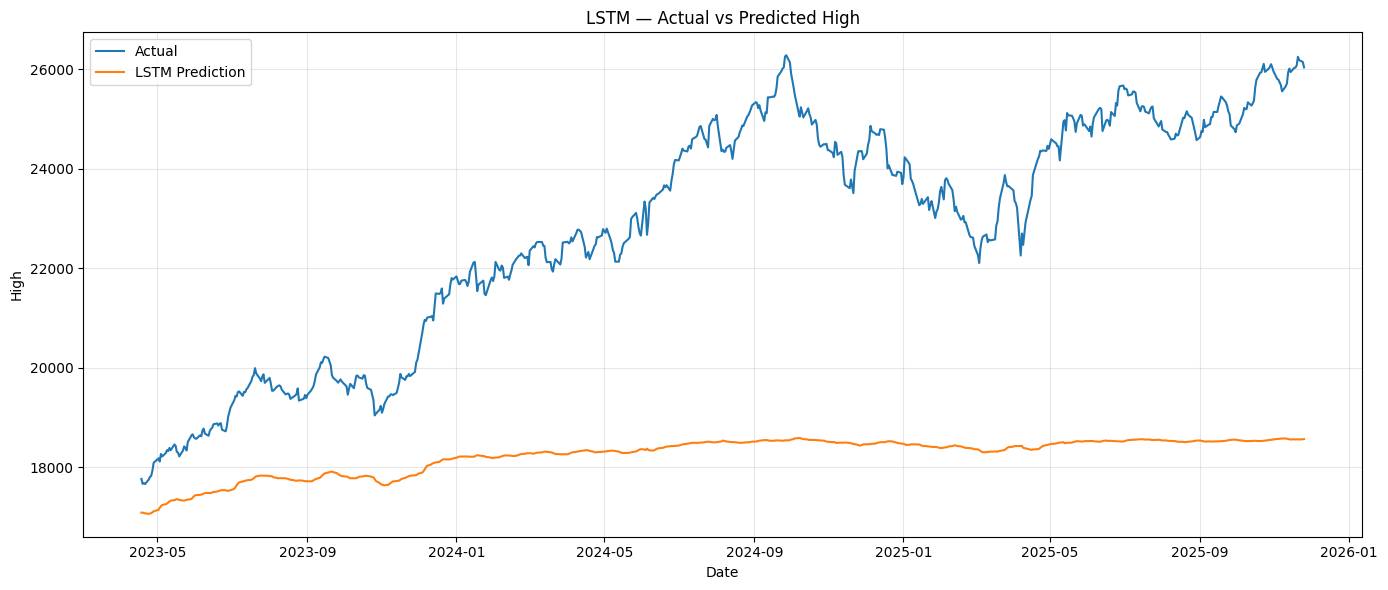

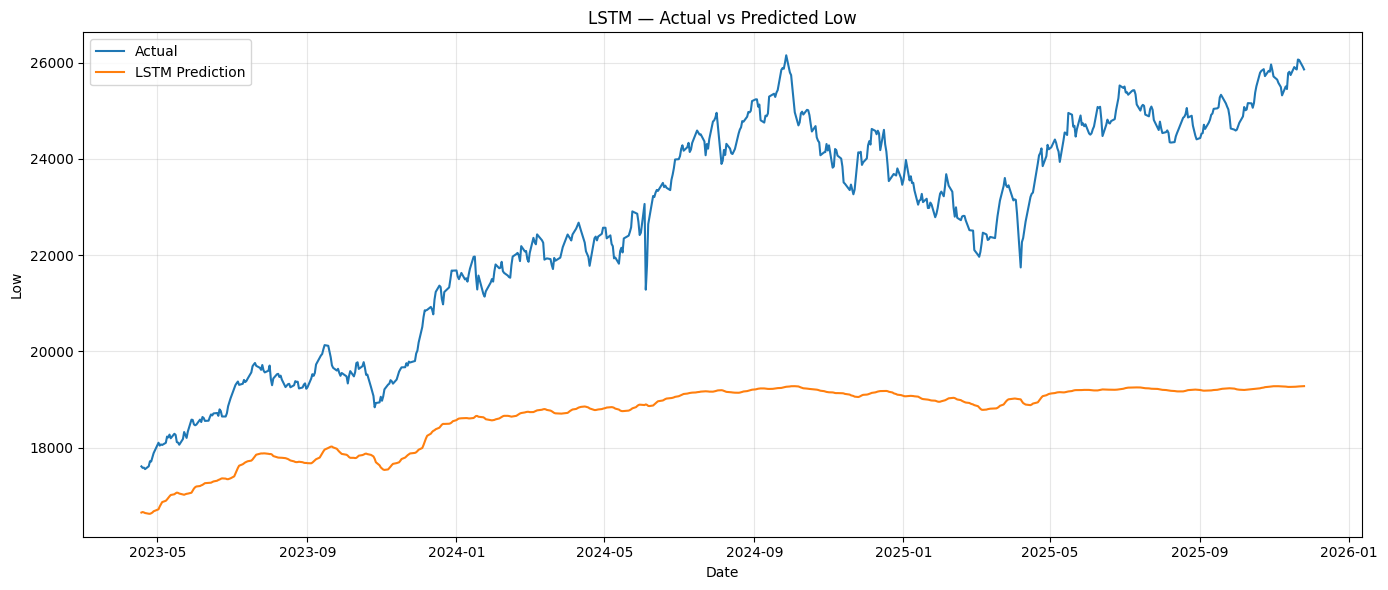

In [14]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in TARGETS:

    _, _, metrics, prediction_df = (
        lstm_results[target]
    )

    plt.figure(figsize=(14, 6))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Actual"],
        label="Actual"
    )

    plt.plot(
        prediction_df["Date"],
        prediction_df["Predicted"],
        label="LSTM Prediction"
    )

    plt.xlabel("Date")
    plt.ylabel(target)

    plt.title(
        f"LSTM — Actual vs Predicted {target}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Actual_vs_Predicted.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

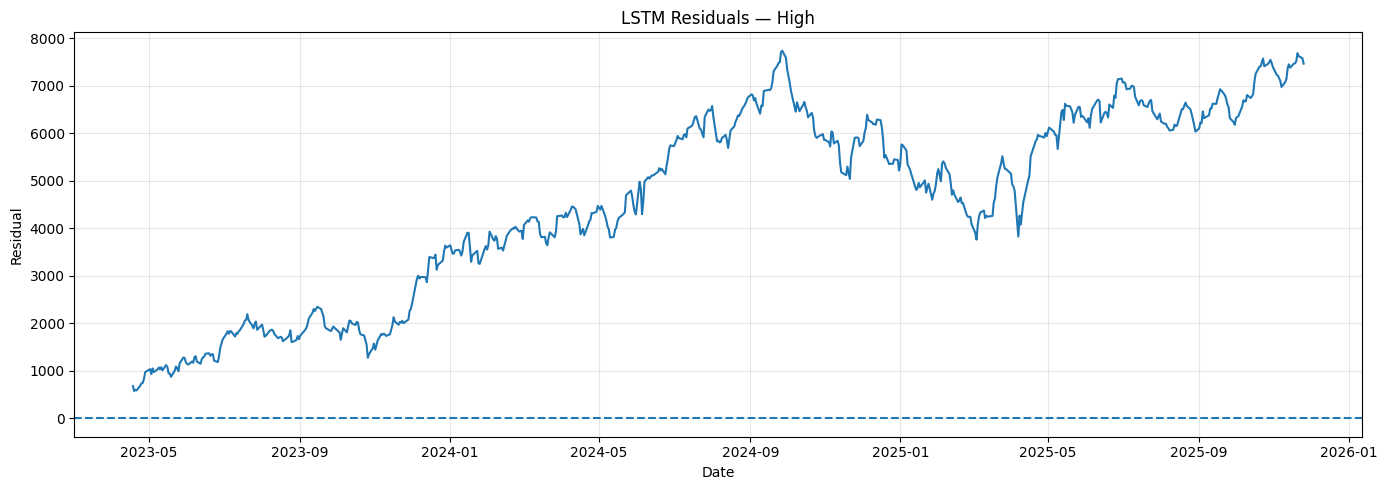

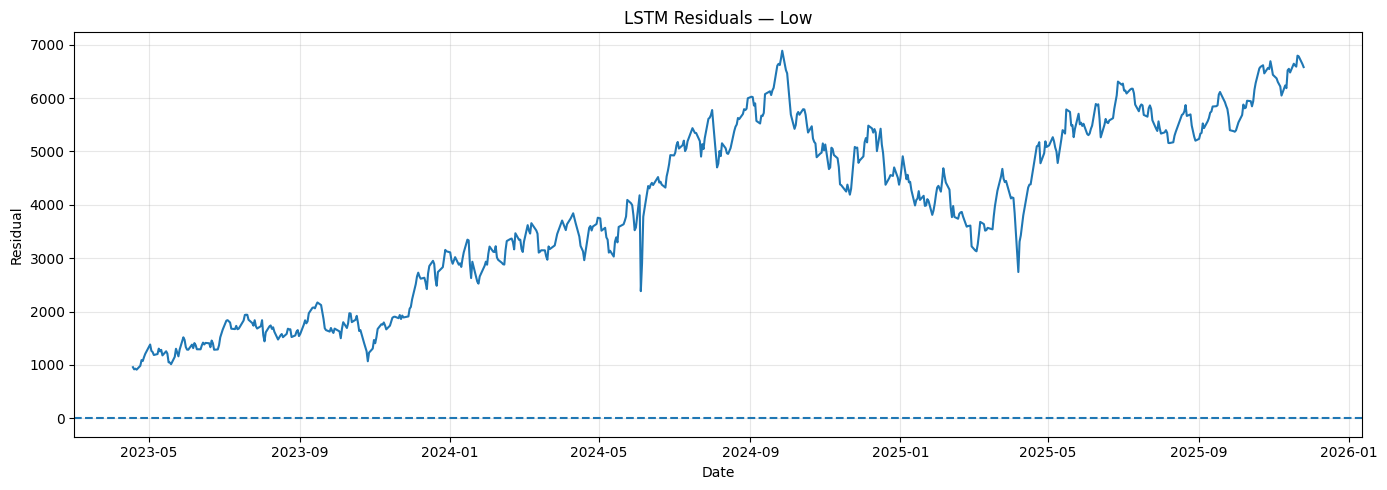

In [15]:
# ============================================================
# RESIDUAL ANALYSIS
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    prediction_df["Residual"] = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Residual"]
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")
    plt.ylabel("Residual")

    plt.title(
        f"LSTM Residuals — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Residuals.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

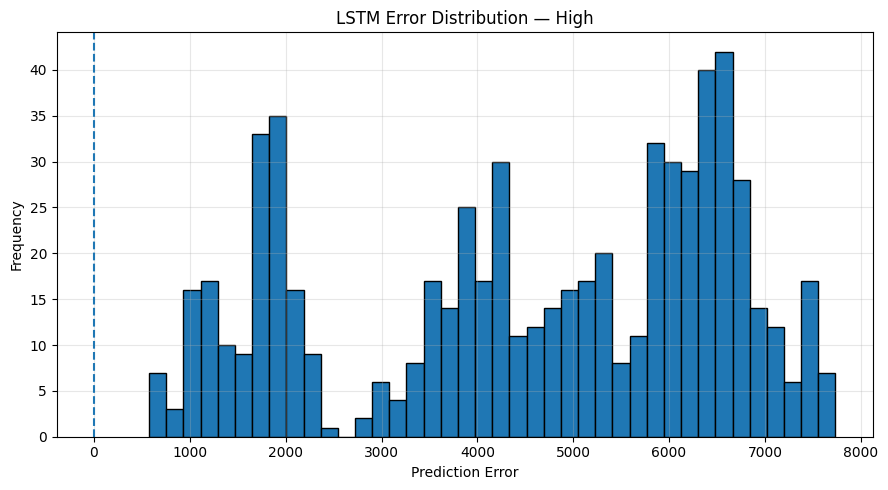

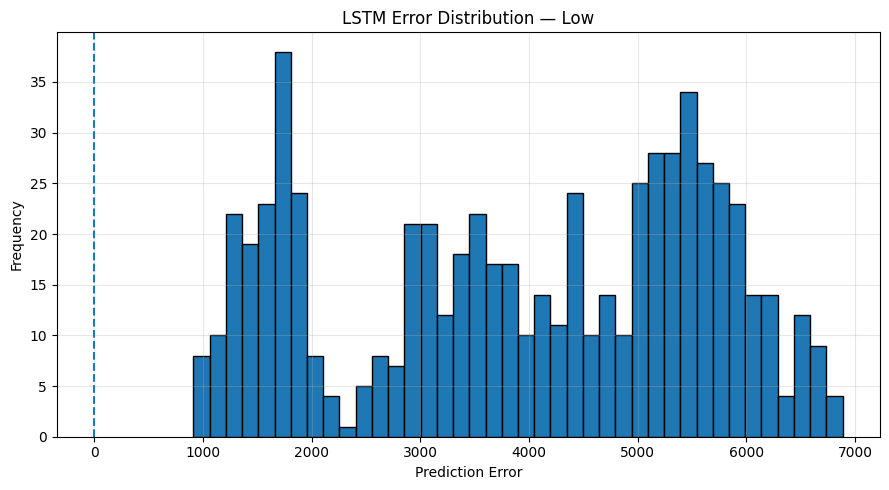

In [16]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

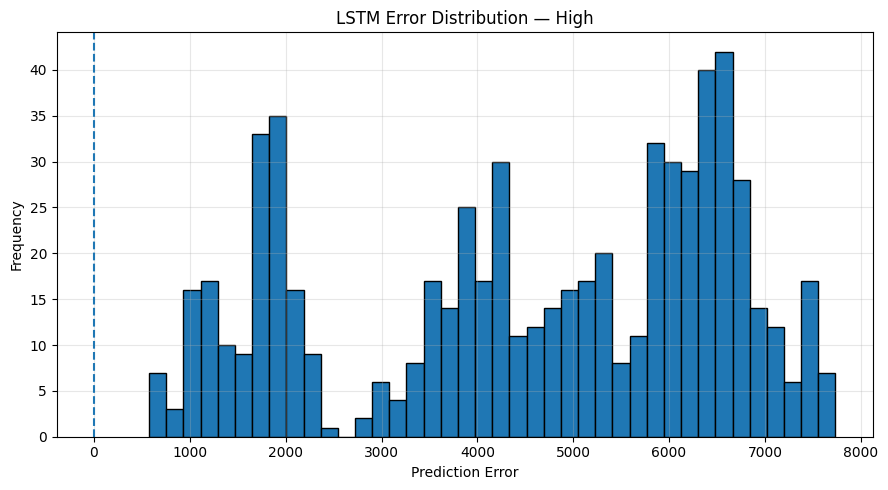

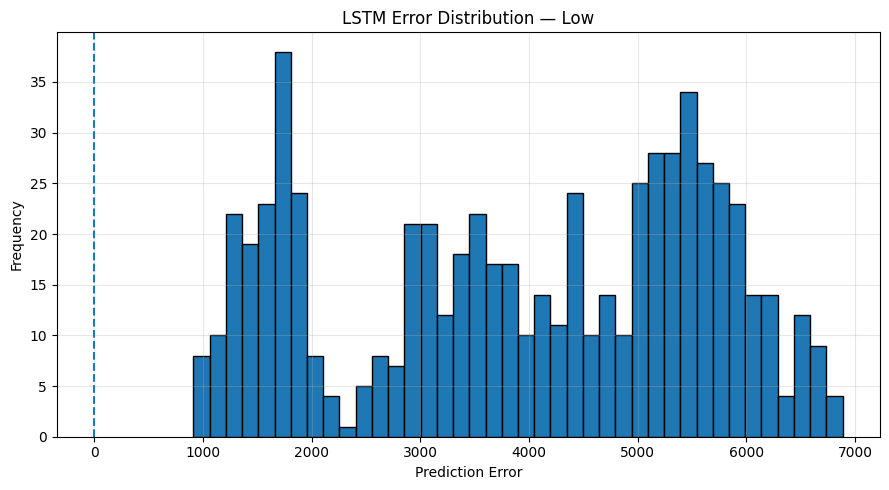

In [17]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# ============================================================
# ConvLSTM-STYLE 1D BASELINE
# NIFTY 50 REGIME-WISE FORECASTING
#
# Target:
#   Next-Day High
#   Next-Day Low
#
# Protocol:
#   70% Train
#   15% Validation
#   15% Test
#
# Input:
#   Previous 25 trading days
#   Open, High, Low, Close
#
# IMPORTANT:
#   Baseline experiment only.
#   NO hyperparameter tuning yet.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dropout,
    Dense,
    BatchNormalization,
    Activation,
    LayerNormalization
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 3. BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# Convolution
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Recurrent layers
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Regularization
DROPOUT = 0.20

# Dense
DENSE_UNITS = 16

# Optimizer
LEARNING_RATE = 0.001

# Training
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 4. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 5. VERIFY DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 6. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 7. MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2010-12-31"
    ),

    "DF2": (
        "2011-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2021-12-31"
    ),

    "DF4": (
        "2022-01-01",
        None
    )
}


# ============================================================
# 8. NORMALIZED NEXT-DAY TARGETS
# ============================================================

# High(t+1) / Close(t)
data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

# Low(t+1) / Close(t)
data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 9. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. VALIDATION / TEST SEQUENCES
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 11. CUSTOM CONVOLUTION-RECURRENT BLOCK
# ============================================================
#
# The idea is:
#
#   Convolution
#       ↓
#   Short-term feature extraction
#       ↓
#   LSTM
#       ↓
#   Temporal memory
#
# This gives the model convolutional processing before
# recurrent temporal modeling.
#
# ============================================================

def build_convlstm_style_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )


    # ========================================================
    # LOCAL TEMPORAL FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CONVOLUTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)


    # ========================================================
    # TEMPORAL RECURRENT MEMORY
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND RECURRENT LAYER
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 14. REGIME LOOP
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE TRAINING — {regime_name}"
    )
    print("=" * 80)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # X / Y
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # 70 / 15 / 15 CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: {len(X_train_raw)}"
    )

    print(
        f"Validation: {len(X_val_raw)}"
    )

    print(
        f"Test: {len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY INPUT SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. TRAIN-ONLY TARGET SCALING
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 18. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 19. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_convlstm_style_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )


    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 23. TEST PREDICTION
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 25. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 27. METRICS — HIGH
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 28. METRICS — LOW
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 29. RESULTS
    # ========================================================

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE RESULTS — {regime_name}"
    )
    print("=" * 80)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"ConvLSTM-Style Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. HIGH PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. LOW PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 100)
print("FINAL ConvLSTM-STYLE BASELINE RESULTS")
print("=" * 100)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "ConvLSTM_style_baseline_results.csv",
    index=False
)

print(
    "\nResults saved:"
    " ConvLSTM_style_baseline_results.csv"
)


# ============================================================
# 37. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "ConvLSTM_style_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved:"
    " ConvLSTM_style_baseline_predictions.xlsx"
)